# Metropolis, exact conditionals and slice sampling

A correct invariant target does not guarantee that a finite chain reaches it. Rejected states must remain in the chain; Gibbs updates can be exact while global mixing fails.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
ROOT=Path.cwd()
if ROOT.name == "notebooks": ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/"src"))
torch.set_num_threads(1)
from sampling_lab.targets import load_target
from sampling_lab.artifacts import sha256
def read(path): return json.loads((ROOT/path).read_text())
def numeric(name): return np.load(ROOT/"assets/source_data"/(name+".npz"),allow_pickle=False)
%matplotlib inline


## Independent implementation check

rwm acceptance 0.39 mean [ 1.63712645 -2.38417903]
gibbs acceptance 1.0 mean [ 1.81793785 -2.18032798]
slice acceptance 1.0 mean [ 1.88393717 -2.10057488]


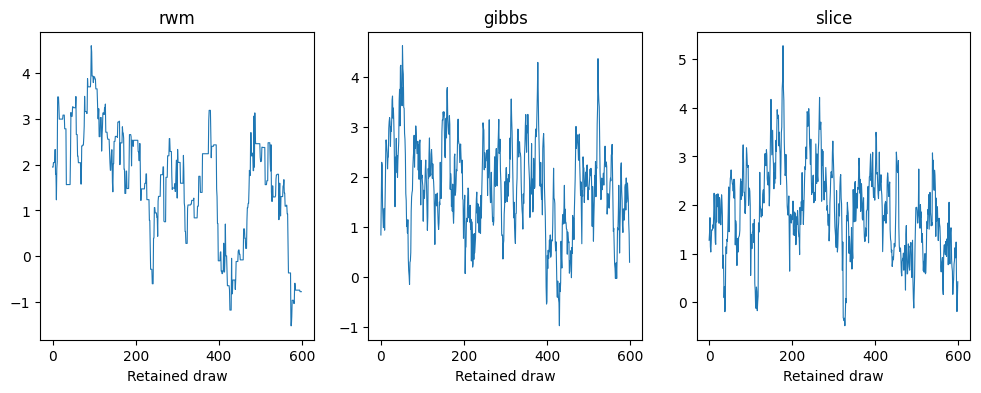

In [2]:
from sampling_lab.samplers import run_chain
methods=["rwm","gibbs","slice"]
target=load_target("gaussian");fig,axes=plt.subplots(1,3,figsize=(12,4))
for ax,method in zip(axes,methods):
 result=run_chain(target,method,np.array([5.,-5.]),600,200,.6,41)
 assert result["samples"].shape==(600,2)
 ax.plot(result["samples"][:,0],lw=.8);ax.set(title=method,xlabel="Retained draw")
 print(method,"acceptance",result["accepted"].mean(),"mean",result["samples"].mean(0))
plt.show()

## Inspect measured evidence

In [3]:
from sampling_lab.samplers import gaussian_gibbs
Q=target.precision;x=np.array([.5,-.5]);conditional=target.mean[0]-Q[0,1]*(x[1]-target.mean[1])/Q[0,0]
print("First-coordinate conditional mean",conditional,"variance",1/Q[0,0])
records=pd.read_csv(ROOT/"docs/sampling_comparison.csv")
display(records[(records.target=="gaussian")&records.method.isin(methods)][["method","max_rhat","min_bulk_ess","convergence_flag"]])

First-coordinate conditional mean 3.425 variance 0.09750000000000003


,method,max_rhat,min_bulk_ess,convergence_flag
26,gibbs,1.009634,396.223664,False
27,gibbs,1.009634,396.223664,False
34,rwm,1.043379,114.440188,False
35,rwm,1.065710,75.254683,False
36,slice,1.032332,174.557730,False


## Interpretation and next step

Read the [theory](../docs/theory.md), [diagnostic scope](../docs/diagnostics.md), and [data protocol](../docs/data_and_protocols.md). Change one declared preset in a separate output directory; keep warmup, test evaluation and model selection distinct. The [interactive explorer](../docs/explorer.html) exposes the complete recorded comparisons.